# Machine Learning

b1: đọc bộ dữ liệu sinh viên và xem qua một lượt

b2: làm quen hàm sigmoid bằng tay trước khi gọi thư viện

b3: để scikit‐learn tìm w và b từ dữ liệu thật.

b4: chia dữ liệu rồi chấm điểm mô hình bằng bốn thước đo.

b5: tự áp ngưỡng và xem precision với recall đổi ra sao.

b6: thêm điểm giữa kỳ làm biến thứ hai.

Đọc dữ liệu

In [2]:
import pandas as pd
df = pd.read_csv("sinh_vien.csv")
print("Kich thuoc bang (so dong, so cot):", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()
# Cột qua_mon chỉ có hai giá trị, đếm số lần xuất hiện từng giá trị
print("So sinh vien theo ket qua:")
print(df["qua_mon"].value_counts())
print()
print()
print("Ty le qua mon:", round(df["qua_mon"].mean(), 4))
# So sánh số giờ ôn trung bình của hai nhóm
print("So gio on trung binh theo nhom:")
print(df.groupby("qua_mon")["gio_on"].mean().round(2))

Kich thuoc bang (so dong, so cot): (120, 3)

Nam dong dau tien:
   gio_on  diem_giua_ky  qua_mon
0     5.5           3.0        0
1    19.0           6.0        1
2    14.0           7.7        0
3    11.0           3.1        0
4    10.5           5.8        1

So sinh vien theo ket qua:
qua_mon
1    71
0    49
Name: count, dtype: int64


Ty le qua mon: 0.5917
So gio on trung binh theo nhom:
qua_mon
0     8.29
1    19.89
Name: gio_on, dtype: float64


cài đặt và kiểm chứng

In [3]:

import numpy as np
def sigmoid(z):
  return 1 / (1 + np.exp(-z))
  print("Bang gia tri cua ham sigmoid")
print(" z sigmoid(z)")
for z in [-6,-4,-2,-1, 0, 1, 2, 4, 6]:
  print(f"{z:3d} {sigmoid(z):.4f}")
  print()
print("Kiem tra sigmoid(‐z) = 1‐ sigmoid(z):")
for z in [1.0, 2.5, 3.7]:
  trai = sigmoid(-z)
  phai = 1 - sigmoid(z)
  print(f" z = {z}: {trai:.6f} va {phai:.6f}")
print()

w, b = 0.4,-5.0
print(f"Mo hinh gia dinh: w = {w}, b = {b}")
print(" So gio on z = w*x + b Xac suat qua mon")
for gio in [5, 10, 12.5, 15, 20, 25]:
  z = w * gio + b
  print(f" {gio:5.1f} {z:6.2f}  {sigmoid(z):.4f}")

 z sigmoid(z)
 -6 0.0025

 -4 0.0180

 -2 0.1192

 -1 0.2689

  0 0.5000

  1 0.7311

  2 0.8808

  4 0.9820

  6 0.9975

Kiem tra sigmoid(‐z) = 1‐ sigmoid(z):
 z = 1.0: 0.268941 va 0.268941
 z = 2.5: 0.075858 va 0.075858
 z = 3.7: 0.024127 va 0.024127

Mo hinh gia dinh: w = 0.4, b = -5.0
 So gio on z = w*x + b Xac suat qua mon
   5.0  -3.00  0.0474
  10.0  -1.00  0.2689
  12.5   0.00  0.5000
  15.0   1.00  0.7311
  20.0   3.00  0.9526
  25.0   5.00  0.9933


Ba bước quen thuộc

In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("sinh_vien.csv")

X = df[["gio_on"]]
y = df["qua_mon"]
mo_hinh = LogisticRegression()
mo_hinh.fit(X, y)
w = float(mo_hinh.coef_[0][0])
b = float(mo_hinh.intercept_[0])
print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

# Số giờ ôn mà mô hình phân vân đúng năm mươi năm mươi
print(f"So gio on ung voi xac suat 0.5: {-b / w:.2f} gio")
print()
can_moi = pd.DataFrame({"gio_on": [5.0, 10.0, 13.0, 20.0, 28.0]})
xac_suat = mo_hinh.predict_proba(can_moi)[:, 1]
nhan = mo_hinh.predict(can_moi)
print("Du doan cho nam ban moi:")
print(" So gio on Xac suat qua Nhan mo hinh dua ra")
for gio, p, n in zip(can_moi["gio_on"], xac_suat, nhan):
    print(f" {gio:5.1f} {p:.4f} {n}")

He so goc w = 0.392819
He so chan b = -5.064890

So gio on ung voi xac suat 0.5: 12.89 gio

Du doan cho nam ban moi:
 So gio on Xac suat qua Nhan mo hinh dua ra
   5.0 0.0431 0
  10.0 0.2429 0
  13.0 0.5104 1
  20.0 0.9422 1
  28.0 0.9974 1


Chia dữ liệu rồi chấm

In [5]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,

precision_score, recall_score)
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]

y = df["qua_mon"]
# stratify=y giữ đúng tỷ lệ qua và rớt ở cả hai phần sau khi chia
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("So sinh vien de hoc :", len(X_train))
print("So sinh vien de kiem tra:", len(X_test))
print()
mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)

y_pred = mo_hinh.predict(X_test)
# Thứ tự bốn ô do scikit‐learn quy định là TN, FP, FN, TP
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f" TN = {tn:2d} doan rot, that su rot")
print(f" FP = {fp:2d} doan qua, that ra rot")
print(f" FN = {fn:2d} doan rot, that ra qua")
print(f" TP = {tp:2d} doan qua, that su qua")
print()

print(f"Accuracy = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall = {recall_score(y_test, y_pred):.4f}")
print(f"F1 = {f1_score(y_test, y_pred):.4f}")

print()

# Tự tính lại bằng tay để đối chiếu với thư viện
print("Tu tinh lai bang cong thuc:")
n = len(y_test)
print(f" Accuracy = ({tp} + {tn}) / {n} = {(tp + tn) / n:.4f}")
print(f" Precision = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")
print(f" Recall = {tp} / ({tp} + {fn}) = {tp / (tp + fn):.4f}")

So sinh vien de hoc : 90
So sinh vien de kiem tra: 30

Ma tran nham lan
 TN =  9 doan rot, that su rot
 FP =  3 doan qua, that ra rot
 FN =  1 doan rot, that ra qua
 TP = 17 doan qua, that su qua

Accuracy = 0.8667
Precision = 0.8500
Recall = 0.9444
F1 = 0.8947

Tu tinh lai bang cong thuc:
 Accuracy = (17 + 9) / 30 = 0.8667
 Precision = 17 / (17 + 3) = 0.8500
 Recall = 17 / (17 + 1) = 0.9444


tự áp ngưỡng

In [7]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]

y = df["qua_mon"]
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, random_state=17, stratify=y
)

p = mo_hinh.predict_proba(X_test)[:, 1]

print()

print("Nguong So ban bi doan la qua Precision Recall")
for nguong in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
  y_pred = (p >= nguong).astype(int)
  pre = precision_score(y_test, y_pred, zero_division=1)
  rec = recall_score(y_test, y_pred, zero_division=0)
  print(f" {nguong:.1f}  {y_pred.sum():3d}"
        f"  {pre:.4f} {rec:.4f}")
print("Doc bang tren tu duoi len:")

print(" Nguong cang cao thi mo hinh cang kho tinh,")
print(" precision tang nhung recall giam. Nguong thap thi nguoc lai.")


Nguong So ban bi doan la qua Precision Recall
 0.2   24  0.7500 1.0000
 0.3   20  0.8500 0.9444
 0.4   20  0.8500 0.9444
 0.5   20  0.8500 0.9444
 0.6   16  1.0000 0.8889
 0.7   15  1.0000 0.8333
 0.8   13  1.0000 0.7222
Doc bang tren tu duoi len:
 Nguong cang cao thi mo hinh cang kho tinh,
 precision tang nhung recall giam. Nguong thap thi nguoc lai.


them bien dau vao

In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("sinh_vien.csv")
y = df["qua_mon"]

mo_hinh_final = None # To store the LogisticRegression model for the 2-variable case
X_final = None # To store the X DataFrame for the 2-variable case

for ten, cot in [("Mot bien", ["gio_on"]),
                 ("Hai bien", ["gio_on", "diem_giua_ky"])]:
  X_current = df[cot]

  X_train, X_test, y_train, y_test = train_test_split(
    X_current, y, test_size=0.25, random_state=17, stratify=y
  )
  mo_hinh = LogisticRegression().fit(X_train, y_train)
  do_chinh_xac = accuracy_score(y_test, mo_hinh.predict(X_test))
  print(f"{ten}: accuracy tren tap kiem tra = {do_chinh_xac:.4f}")

  if ten == "Hai bien":
      mo_hinh_final = mo_hinh
      X_final = X_current # Store X_current for the two-variable case

print()

if mo_hinh_final is not None and X_final is not None:
    print("He so cua tung bien:")
    for ten_cot, he_so in zip(X_final.columns, mo_hinh_final.coef_[0]):
      print(f" {ten_cot:14s} {he_so:+.4f}")
    print(f" {'he so chan':14s} {mo_hinh_final.intercept_[0]:+.4f}")
else:
    print("Error: Could not retrieve model for 'Hai bien' case to print coefficients.")


print()
print("ca hai he so deu duong, nghia la on nhieu hon va")
print("diem giua ky cao hon deu lam tang xac suat qua mon")

Mot bien: accuracy tren tap kiem tra = 0.8667
Hai bien: accuracy tren tap kiem tra = 0.9000

He so cua tung bien:
 gio_on         +0.3035
 diem_giua_ky   +0.5885
 he so chan     -6.9811

ca hai he so deu duong, nghia la on nhieu hon va
diem giua ky cao hon deu lam tang xac suat qua mon


# BAI TAP

Bài tập 1: Thống kê theo nhóm
Đọc bộ dữ liệu rồi in ra ba con số. Số bạn có điểm giữa kỳ từ 7 trở lên, tỷ lệ qua môn của
riêng nhóm đó, và tỷ lệ qua môn của nhóm còn lại.
Gợi ý, dùng phép lọc theo điều kiện của pandas rồi lấy .mean() của cột qua_mon. Nhận xét
một câu về việc điểm giữa kỳ có phân biệt được hai nhóm hay không.

In [11]:
import pandas as pd

df = pd.read_csv("sinh_vien.csv")

# Nhóm có điểm giữa kỳ >= 7
nhom_cao = df[df["diem_giua_ky"] >= 7]
# Nhóm còn lại
nhom_thap = df[df["diem_giua_ky"] < 7]

print("So ban co diem giua ky >= 7:", len(nhom_cao))
print("Ty le qua mon cua nhom nay:", round(nhom_cao["qua_mon"].mean(), 4))
print("Ty le qua mon cua nhom con lai:", round(nhom_thap["qua_mon"].mean(), 4))

So ban co diem giua ky >= 7: 31
Ty le qua mon cua nhom nay: 0.9032
Ty le qua mon cua nhom con lai: 0.4831


Bài tập 2: Vẽ hàm sigmoid
Vẽ đồ thị hàm sigmoid với z chạy từ −8 tới 8, lưu thành tệp sigmoid.png. Trên cùng hình,
vẽ thêm một đường ngang tại mức 0.5 và một đường dọc tại z = 0.
Gợi ý, dùng np.linspace, plt.plot, plt.axhline, plt.axvline và plt.savefig.

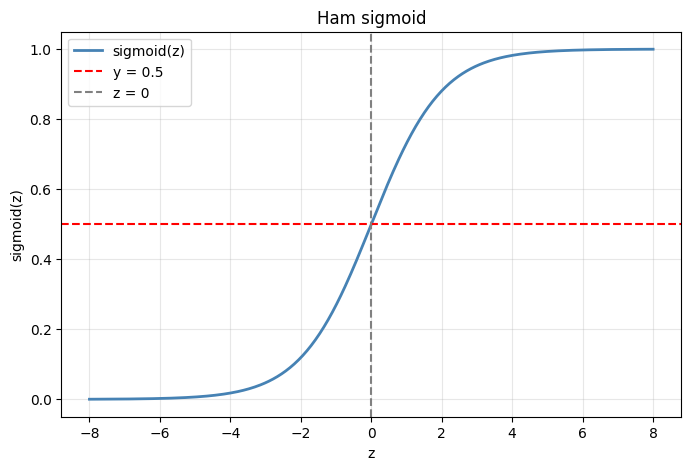

In [12]:
"""Ve do thi ham sigmoid."""

import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 400)
y = sigmoid(z)

plt.figure(figsize=(8, 5))
plt.plot(z, y, color="steelblue", linewidth=2, label="sigmoid(z)")
plt.axhline(y=0.5, color="red", linestyle="--", label="y = 0.5")
plt.axvline(x=0, color="gray", linestyle="--", label="z = 0")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Ham sigmoid")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("sigmoid.png", dpi=150)
plt.show()

Bài tập 3: Dự đoán cho một bạn cụ thể
Khớp lại mô hình một biến như ở mục 4, rồi viết một hàm du_doan(gio) nhận vào số giờ
ôn và in ra ba thứ. Giá trị z, xác suất qua môn, và nhãn theo ngưỡng 0.5.
Gọi hàm đó với các giá trị 3, 8, 12.89, 18 và 26 giờ. Giải thích vì sao với 12.89 giờ thì xác
suất ra gần đúng 0.5.

In [14]:
"""Du doan cho mot ban cu the."""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

mo_hinh = LogisticRegression()
mo_hinh.fit(X, y)

w = float(mo_hinh.coef_[0][0])
b = float(mo_hinh.intercept_[0])

def du_doan(gio):
    z = w * gio + b
    p = sigmoid(z)
    nhan = 1 if p >= 0.5 else 0
    print(f"Gio on = {gio:6.2f} | z = {z:8.4f} | "
          f"Xac suat qua mon = {p:.4f} | Nhan = {nhan}")

print(f"w = {w:.6f}, b = {b:.6f}")
print(f"Diem hòa vốn: {-b/w:.4f} gio")
print()
for gio in [3, 8, 12.89, 18, 26]:
    du_doan(gio)

w = 0.392819, b = -5.064890
Diem hòa vốn: 12.8937 gio

Gio on =   3.00 | z =  -3.8864 | Xac suat qua mon = 0.0201 | Nhan = 0
Gio on =   8.00 | z =  -1.9223 | Xac suat qua mon = 0.1276 | Nhan = 0
Gio on =  12.89 | z =  -0.0015 | Xac suat qua mon = 0.4996 | Nhan = 0
Gio on =  18.00 | z =   2.0059 | Xac suat qua mon = 0.8814 | Nhan = 1
Gio on =  26.00 | z =   5.1484 | Xac suat qua mon = 0.9942 | Nhan = 1


Bài tập 4: Tự tính bốn thước đo
Chép tệp c4_danh_gia.py sang baitap02 rồi bỏ hết các hàm accuracy_score,
precision_score, recall_score, f1_score của scikit-learn đi. Tự tính bốn con số đó
chỉ từ bốn số TP, TN, FP, FN bằng công thức ở mục 5.
So kết quả tự tính với kết quả thư viện in ra trong tài liệu, hai bên phải khớp. Nộp cả phần
mã tự tính và ảnh chụp kết quả.

In [16]:
"""Tu tinh bon thuoc do tu TP, TN, FP, FN."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}")
print()

# Tự tính bốn thước đo bằng công thức ở mục 5
n = len(y_test)
accuracy  = (tp + tn) / n
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = (2 * precision * recall / (precision + recall)
      if (precision + recall) > 0 else 0)

print(f"Accuracy  = ({tp} + {tn}) / {n} = {accuracy:.4f}")
print(f"Precision = {tp} / ({tp} + {fp}) = {precision:.4f}")
print(f"Recall    = {tp} / ({tp} + {fn}) = {recall:.4f}")
print(f"F1        = 2 * {precision:.4f} * {recall:.4f} / "
      f"({precision:.4f} + {recall:.4f}) = {f1:.4f}")

TP = 17, TN = 9, FP = 3, FN = 1

Accuracy  = (17 + 9) / 30 = 0.8667
Precision = 17 / (17 + 3) = 0.8500
Recall    = 17 / (17 + 1) = 0.9444
F1        = 2 * 0.8500 * 0.9444 / (0.8500 + 0.9444) = 0.8947


Bài tập 5: Dò ngưỡng tốt nhất theo F1
Cho ngưỡng chạy từ 0.05 tới 0.95, mỗi bước 0.05. Với mỗi ngưỡng, tính F1 trên tập kiểm
tra rồi in ra thành bảng. Cuối cùng in ra ngưỡng cho F1 cao nhất.
Nhận xét một câu: ngưỡng tốt nhất theo F1 có đúng bằng 0.5 không? Gợi ý, dùng
np.arange(0.05, 1.0, 0.05) và hàm f1_score với tham số zero_division=0.

In [17]:
"""Do nguong tot nhat theo F1."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)
p = mo_hinh.predict_proba(X_test)[:, 1]

nguong_tot_nhat = None
f1_tot_nhat = -1.0

print(f"{'Nguong':>7} {'F1':>8}")
for nguong in np.arange(0.05, 1.0, 0.05):
    y_pred = (p >= nguong).astype(int)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    print(f"{nguong:7.2f} {f1:8.4f}")
    if f1 > f1_tot_nhat:
        f1_tot_nhat = f1
        nguong_tot_nhat = nguong

print()
print(f"Nguong tot nhat theo F1: {nguong_tot_nhat:.2f} "
      f"voi F1 = {f1_tot_nhat:.4f}")
print("Nhan xet: nguong tot nhat theo F1 khong nhat thiet bang 0.5.")

 Nguong       F1
   0.05   0.7826
   0.10   0.8182
   0.15   0.8182
   0.20   0.8571
   0.25   0.9000
   0.30   0.8947
   0.35   0.8947
   0.40   0.8947
   0.45   0.8947
   0.50   0.8947
   0.55   0.8889
   0.60   0.9412
   0.65   0.9412
   0.70   0.9091
   0.75   0.8750
   0.80   0.8387
   0.85   0.8000
   0.90   0.5600
   0.95   0.4348

Nguong tot nhat theo F1: 0.60 voi F1 = 0.9412
Nhan xet: nguong tot nhat theo F1 khong nhat thiet bang 0.5.


Bài tập 6: Đổi lớp dương rồi chấm lại
Ở mục 5 ta luôn lấy lớp dương là qua môn. Bây giờ hãy chấm điểm cho lớp rớt môn, tức
lớp 0.
Gợiý, thêmthamsốpos_label=0vàoprecision_scorevàrecall_score. Inraprecision
và recall của lớp 0 rồi so với con số của lớp 1 trong tài liệu. Giải thích bằng lời vì sao hai
bộ số khác nhau, dù mô hình và dữ liệu không đổi chút nào.

In [18]:
"""Doi lop duong sang lop 0 (rot mon) roi cham lai."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score

df = pd.read_csv("sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

# Lop 1 (qua mon)
print("Lop 1 (qua mon):")
print(f"  Precision = {precision_score(y_test, y_pred, pos_label=1):.4f}")
print(f"  Recall    = {recall_score(y_test, y_pred, pos_label=1):.4f}")
print()

# Lop 0 (rot mon)
print("Lop 0 (rot mon):")
print(f"  Precision = {precision_score(y_test, y_pred, pos_label=0):.4f}")
print(f"  Recall    = {recall_score(y_test, y_pred, pos_label=0):.4f}")

Lop 1 (qua mon):
  Precision = 0.8500
  Recall    = 0.9444

Lop 0 (rot mon):
  Precision = 0.9000
  Recall    = 0.7500
